# Complete Controlled Comparison: 2026 PhishSigma++ vs Baseline Models

In [ ]:
!pip -q install -U scikit-learn pandas matplotlib scipy statsmodels tldextract kagglehub

In [ ]:
import os, re, gc, json, time, random, shutil, string, warnings, email, mailbox, tarfile, urllib.request
from pathlib import Path
from email import policy
from email.parser import BytesParser
from urllib.parse import urlparse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MaxAbsScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print('Setup complete. Seed:', SEED)

Setup complete. Seed: 42


## 1. Configuration
Our controlled protocol, informed by the paper's reported PSO settings (30 particles, omega=0.7, c1=c2=1.5, lambda=0.015). Iteration count is reduced from the paper's 50 to a runnable 25 for a student project; note this explicitly when reporting results.

In [ ]:
PROJECT_DIR = Path('/content/phishing_2026_project')
DATA_DIR = PROJECT_DIR / 'data'
RAW_DIR = DATA_DIR / 'raw'
RESULTS_DIR = PROJECT_DIR / 'results'
for d in [DATA_DIR, RAW_DIR, RESULTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Our controlled protocol (informed by, not identical to, the paper's settings).
TEST_SIZE = 0.25
N_ENTITY_TYPES = 40          # matches Appendix Table A1
PSO_N_PARTICLES = 30         # matches the paper
PSO_N_ITERS = 25             # paper uses 50; reduced for a runnable student project
PSO_OMEGA = 0.7              # matches the paper
PSO_C1 = PSO_C2 = 1.5        # matches the paper (paper text: c1=c2=1.5)
PSO_SPARSITY_LAMBDA = 0.015  # matches the paper
CV_FOLDS_FOR_FITNESS = 3     # inner CV used only inside the PSO fitness function
GOOD_WORD_RATES = [0.0, 0.2, 0.4, 0.6, 0.8]  # matches the paper's robustness sweep

print('Config loaded')

Config loaded


## 2. Download the four raw-email corpora identified by the paper
Enron (benign, Kaggle mirror) + Phishing Pot (malicious, GitHub) + Nazario (malicious, monkey.org mbox) + SpamAssassin (benign/malicious, Apache public corpus). Each source is wrapped in try/except; missing sources are skipped with a manual-download instruction rather than crashing the notebook.

In [ ]:
# ---------------------------------------------------------------------------
# Data sources (same four corpora identified in the paper, Section 4.1):
#   1. Enron          - benign mail, via the Kaggle mirror (has raw headers).
#   2. Phishing Pot    - public phishing .eml snapshot, via GitHub (git clone / zip).
#   3. Nazario         - phishing mbox corpus, via monkey.org.
#   4. SpamAssassin    - spam (mapped to malicious) + ham, via the Apache public corpus.
# Each block is wrapped in try/except: if a source is unreachable from your runtime,
# it is skipped with a printed warning and a manual-download instruction, and the
# remaining pipeline runs on whatever sources did download successfully.
# ---------------------------------------------------------------------------

def safe_download(url, dest_path, description):
    try:
        if not Path(dest_path).exists():
            urllib.request.urlretrieve(url, dest_path)
        print(f'[ok] {description}: {dest_path}')
        return True
    except Exception as e:
        print(f'[skip] {description} failed ({e}). '
              f'Manually download {url} and place it at {dest_path}, then rerun this cell.')
        return False

# 1. Enron (benign) - Kaggle mirror with raw message text including headers.
enron_dir = RAW_DIR / 'enron'
enron_dir.mkdir(exist_ok=True)
try:
    import kagglehub
    enron_path = kagglehub.dataset_download('wcukierski/enron-email-dataset', output_dir=str(enron_dir))
    print('[ok] Enron (Kaggle mirror) downloaded to:', enron_path)
except Exception as e:
    print('[skip] Enron Kaggle download failed:', e)
    print('Manual fallback: https://www.kaggle.com/datasets/wcukierski/enron-email-dataset '
          f'-> place emails.csv into {enron_dir}')

# 2. Phishing Pot (phishing, raw .eml with headers) - GitHub snapshot.
phishing_pot_dir = RAW_DIR / 'phishing_pot'
try:
    if not phishing_pot_dir.exists():
        os.system(f'git clone --depth 1 https://github.com/rf-peixoto/phishing_pot "{phishing_pot_dir}"')
    print('[ok] Phishing Pot cloned to:', phishing_pot_dir)
except Exception as e:
    print('[skip] Phishing Pot clone failed:', e)
    print('Manual fallback: https://github.com/rf-peixoto/phishing_pot -> download ZIP into', phishing_pot_dir)

# 3. Nazario phishing corpus (mbox format, raw headers).
nazario_dir = RAW_DIR / 'nazario'
nazario_dir.mkdir(exist_ok=True)
nazario_url = 'https://monkey.org/~jose/phishing/phishing3.mbox'
safe_download(nazario_url, nazario_dir / 'phishing3.mbox',
              'Nazario phishing corpus (mbox)')
print('If this 404s, browse https://monkey.org/~jose/phishing/ for the current filename '
      'and update nazario_url above.')

# 4. SpamAssassin public corpus (ham + spam, raw headers).
sa_dir = RAW_DIR / 'spamassassin'
sa_dir.mkdir(exist_ok=True)
sa_files = {
    'easy_ham': 'https://spamassassin.apache.org/old/publiccorpus/20030228_easy_ham.tar.bz2',
    'hard_ham': 'https://spamassassin.apache.org/old/publiccorpus/20030228_hard_ham.tar.bz2',
    'spam': 'https://spamassassin.apache.org/old/publiccorpus/20030228_spam.tar.bz2',
}
for name, url in sa_files.items():
    ok = safe_download(url, sa_dir / f'{name}.tar.bz2', f'SpamAssassin {name}')
    if ok:
        try:
            with tarfile.open(sa_dir / f'{name}.tar.bz2', 'r:bz2') as tf:
                tf.extractall(sa_dir)
        except Exception as e:
            print(f'[warn] could not extract {name}:', e)

Using Colab cache for faster access to the 'enron-email-dataset' dataset.
[ok] Enron (Kaggle mirror) downloaded to: /kaggle/input/enron-email-dataset
[ok] Phishing Pot cloned to: /content/phishing_2026_project/data/raw/phishing_pot
[ok] Nazario phishing corpus (mbox): /content/phishing_2026_project/data/raw/nazario/phishing3.mbox
If this 404s, browse https://monkey.org/~jose/phishing/ for the current filename and update nazario_url above.
[ok] SpamAssassin easy_ham: /content/phishing_2026_project/data/raw/spamassassin/easy_ham.tar.bz2
[ok] SpamAssassin hard_ham: /content/phishing_2026_project/data/raw/spamassassin/hard_ham.tar.bz2
[ok] SpamAssassin spam: /content/phishing_2026_project/data/raw/spamassassin/spam.tar.bz2


## 3. Parse every source into a common (raw_message, label, source) table

In [ ]:
# ---------------------------------------------------------------------------
# Parse every source into a common list of dicts: {raw_message (str), label (0/1), source}
# label: 1 = malicious (phishing / spam), 0 = benign
# ---------------------------------------------------------------------------
records = []

def add_record(raw_bytes_or_str, label, source):
    if isinstance(raw_bytes_or_str, bytes):
        try:
            raw_bytes_or_str = raw_bytes_or_str.decode('utf-8', errors='ignore')
        except Exception:
            return
    if not raw_bytes_or_str or len(raw_bytes_or_str.strip()) == 0:
        return
    records.append({'raw_message': raw_bytes_or_str, 'label': label, 'source': source})

# Enron (benign) - the Kaggle mirror ships a single emails.csv with a 'message' column
# containing the full raw RFC822 text (headers + body).
enron_csvs = list(enron_dir.rglob('emails.csv'))
if enron_csvs:
    enron_df = pd.read_csv(enron_csvs[0], nrows=15000)  # cap for a runnable student project
    msg_col = 'message' if 'message' in enron_df.columns else enron_df.columns[-1]
    for msg in enron_df[msg_col].dropna().tolist():
        add_record(msg, 0, 'enron')
    print('Enron benign records loaded:', sum(r['source'] == 'enron' for r in records))
else:
    print('[skip] No Enron emails.csv found - see the download cell above.')

# Phishing Pot (malicious) - raw .eml files under email/*.eml
pot_files = list(phishing_pot_dir.rglob('*.eml')) if phishing_pot_dir.exists() else []
for fp in pot_files:
    try:
        add_record(fp.read_bytes(), 1, 'phishing_pot')
    except Exception:
        pass
print('Phishing Pot malicious records loaded:', sum(r['source'] == 'phishing_pot' for r in records))

# Nazario (malicious) - mbox format.
nazario_mbox_files = list(nazario_dir.glob('*.mbox'))
for mbox_path in nazario_mbox_files:
    try:
        mbox = mailbox.mbox(str(mbox_path))
        for msg in mbox:
            add_record(msg.as_bytes(), 1, 'nazario')
    except Exception as e:
        print('[warn] could not parse', mbox_path, e)
print('Nazario malicious records loaded:', sum(r['source'] == 'nazario' for r in records))

# SpamAssassin - ham directories are benign, spam directory is malicious (matching the
# paper's choice to map SpamAssassin spam into the positive/malicious class).
for sub in sa_dir.rglob('*'):
    if sub.is_file() and sub.parent.name in {'easy_ham', 'hard_ham', 'spam'} \
            and not sub.name.startswith('.') and sub.suffix == '':
        label = 1 if sub.parent.name == 'spam' else 0
        try:
            add_record(sub.read_bytes(), label, 'spamassassin')
        except Exception:
            pass
print('SpamAssassin records loaded:', sum(r['source'] == 'spamassassin' for r in records))

print('\nTotal raw records assembled:', len(records))
if len(records) == 0:
    raise RuntimeError('No source downloaded successfully. Re-run Cell 7 with a live internet '
                        'connection, or manually place files as instructed in the printed messages.')

raw_df = pd.DataFrame(records)
print(raw_df.groupby(['source', 'label']).size())

[skip] No Enron emails.csv found - see the download cell above.
Phishing Pot malicious records loaded: 12270
[warn] could not parse /content/phishing_2026_project/data/raw/nazario/phishing3.mbox 'ascii' codec can't encode characters in position 4-5: ordinal not in range(128)
Nazario malicious records loaded: 1113
SpamAssassin records loaded: 3

Total raw records assembled: 13386
source        label
nazario       1         1113
phishing_pot  1        12270
spamassassin  0            2
              1            1
dtype: int64


## 4. Typed entity extraction: 40 types across Structural / Content / Keyword groups
Matches Appendix Table A1 of the paper exactly in type count and grouping.

In [ ]:
# ---------------------------------------------------------------------------
# 40 typed entity extractors, grouped as in Appendix Table A1 of the paper:
#   Structural (sender identity x5, routing x4, recipient x3, URL structure x5, attachment x1)
#   Content    (subject x1, body x1)
#   Keyword    (direct-indicator x5, brand/social-eng x6, authority/scare x6, financial x3)
# Every extractor returns a (possibly empty) list of strings: the typed occurrences found.
# ---------------------------------------------------------------------------
ENTITY_TYPES = [
    # Structural: sender identity (5)
    'sender_address', 'sender_display_name', 'sender_domain', 'return_path', 'reply_to',
    # Structural: routing (4)
    'received_hops', 'x_mailer', 'message_id_domain', 'content_type',
    # Structural: recipient (3)
    'recipient_address', 'recipient_domain', 'recipient_username',
    # Structural: URL structure (5)
    'url_actual', 'url_display_text', 'url_domain', 'url_subdomain', 'url_params',
    # Structural: attachment (1)
    'attachment_info',
    # Content (2)
    'subject_text', 'body_text',
    # Keyword: direct indicators (5)
    'kw_urgency', 'kw_action', 'kw_threat', 'kw_financial', 'kw_credential',
    # Keyword: brand / social engineering (6)
    'kw_brand', 'kw_greeting', 'kw_closing', 'kw_link_action', 'kw_time_pressure', 'kw_legal_threat',
    # Keyword: authority / scare (6)
    'kw_government', 'kw_notification', 'kw_tech_jargon', 'kw_scam_prize', 'kw_security_alert', 'kw_account_status',
    # Keyword: financial deception (3)
    'kw_money_transfer', 'kw_personal_info', 'kw_shipping',
]
assert len(ENTITY_TYPES) == N_ENTITY_TYPES, (len(ENTITY_TYPES), N_ENTITY_TYPES)
TYPE_INDEX = {t: i for i, t in enumerate(ENTITY_TYPES)}

KEYWORD_LEXICON = {
    'kw_urgency': ['urgent', 'immediately', 'right away', 'act now', 'asap', 'expire'],
    'kw_action': ['click here', 'verify', 'confirm', 'update your', 'log in', 'sign in'],
    'kw_threat': ['suspend', 'terminate', 'restrict', 'close your account', 'legal action'],
    'kw_financial': ['invoice', 'payment', 'wire transfer', 'refund', 'billing', '$'],
    'kw_credential': ['password', 'username', 'ssn', 'social security', 'pin', 'card number'],
    'kw_brand': ['paypal', 'microsoft', 'apple', 'amazon', 'bank of america', 'netflix', 'irs', 'dhl', 'fedex'],
    'kw_greeting': ['dear customer', 'dear user', 'dear sir', 'dear madam', 'valued customer'],
    'kw_closing': ['regards', 'sincerely', 'best wishes', 'customer support', 'security team'],
    'kw_link_action': ['click the link', 'follow this link', 'download attachment', 'open the attached'],
    'kw_time_pressure': ['within 24 hours', 'today', 'before it', 'deadline', 'final notice'],
    'kw_legal_threat': ['lawsuit', 'legal department', 'court', 'penalty', 'fraud investigation'],
    'kw_government': ['irs', 'social security administration', 'government', 'federal', 'tax refund'],
    'kw_notification': ['notification', 'alert', 'you have received', 'new message', 'delivery notice'],
    'kw_tech_jargon': ['server', 'encryption', 'firewall', 'authentication', 'two-factor'],
    'kw_scam_prize': ['winner', 'congratulations', 'prize', 'lottery', 'claim your reward'],
    'kw_security_alert': ['unusual activity', 'security alert', 'unauthorized access', 'suspicious login'],
    'kw_account_status': ['account suspended', 'account limited', 'account locked', 'verify your account'],
    'kw_money_transfer': ['wire', 'western union', 'bank transfer', 'send money', 'gift card'],
    'kw_personal_info': ['date of birth', 'home address', 'mother\'s maiden name', 'passport'],
    'kw_shipping': ['tracking number', 'package', 'delivery failed', 'shipment', 'courier'],
}

URL_RE = re.compile(r'href=["\\\']?(https?://[^"\'>\s]+)|(?<!\w)(https?://[^\s<>"\')]+)', re.IGNORECASE)
DISPLAY_URL_RE = re.compile(r'<a[^>]*href=["\\\']?(https?://[^"\'>\s]+)["\\\']?[^>]*>(.*?)</a>', re.IGNORECASE | re.DOTALL)


def parse_email(raw_message):
    """Parse a raw RFC822 string into a Python email.message.Message object."""
    try:
        return email.message_from_string(raw_message, policy=policy.compat32)
    except Exception:
        return None


def get_body_text(msg):
    try:
        if msg.is_multipart():
            parts = []
            for part in msg.walk():
                if part.get_content_type() in ('text/plain', 'text/html'):
                    try:
                        parts.append(part.get_payload(decode=True).decode('utf-8', errors='ignore'))
                    except Exception:
                        pass
            return ' '.join(parts)
        else:
            payload = msg.get_payload(decode=True)
            if payload is not None:
                return payload.decode('utf-8', errors='ignore')
            return str(msg.get_payload())
    except Exception:
        return ''


def extract_entities(raw_message):
    """Return dict: entity_type -> list[str] of typed occurrences (possibly empty)."""
    ents = {t: [] for t in ENTITY_TYPES}
    msg = parse_email(raw_message)
    if msg is None:
        ents['body_text'] = [raw_message[:2000]]
        return ents

    def add(t, v):
        if v:
            ents[t].append(str(v).strip().lower())

    from_hdr = msg.get('From', '') or ''
    m = re.search(r'"?([^"<]*)"?\s*<([^>]+)>', from_hdr)
    if m:
        add('sender_display_name', m.group(1))
        add('sender_address', m.group(2))
    elif '@' in from_hdr:
        add('sender_address', from_hdr)
    if ents['sender_address']:
        addr = ents['sender_address'][0]
        if '@' in addr:
            add('sender_domain', addr.split('@')[-1])

    add('return_path', msg.get('Return-Path', ''))
    add('reply_to', msg.get('Reply-To', ''))
    add('x_mailer', msg.get('X-Mailer', ''))
    add('content_type', msg.get_content_type())

    msg_id = msg.get('Message-ID', '') or msg.get('Message-Id', '') or ''
    md = re.search(r'@([\w\.-]+)>?', msg_id)
    if md:
        add('message_id_domain', md.group(1))

    received_headers = msg.get_all('Received', []) or []
    if received_headers:
        ents['received_hops'] = [str(len(received_headers))]

    to_hdr = msg.get('To', '') or ''
    for addr in re.findall(r'[\w\.\+-]+@[\w\.-]+', to_hdr):
        add('recipient_address', addr)
        add('recipient_domain', addr.split('@')[-1])
        add('recipient_username', addr.split('@')[0])

    subject = msg.get('Subject', '') or ''
    add('subject_text', subject)

    body = get_body_text(msg)
    add('body_text', body[:5000])

    if 'attachment' in (msg.get('Content-Disposition', '') or '').lower():
        add('attachment_info', msg.get('Content-Disposition', ''))

    combined_for_urls = (body or '') + ' ' + subject
    for disp_match in DISPLAY_URL_RE.finditer(combined_for_urls):
        actual, display = disp_match.group(1), re.sub('<[^>]+>', '', disp_match.group(2))
        add('url_actual', actual)
        add('url_display_text', display)
        try:
            parsed = urlparse(actual)
            add('url_domain', parsed.netloc)
            netloc_parts = parsed.netloc.split('.')
            if len(netloc_parts) > 2:
                add('url_subdomain', '.'.join(netloc_parts[:-2]))
            if parsed.query:
                add('url_params', parsed.query)
        except Exception:
            pass
    for plain_url in re.findall(r'(?<!href=")https?://[^\s<>"\')]+', combined_for_urls):
        try:
            parsed = urlparse(plain_url)
            add('url_actual', plain_url)
            add('url_domain', parsed.netloc)
        except Exception:
            pass

    combined_lower = (subject + ' ' + body).lower()
    for kw_type, lexicon in KEYWORD_LEXICON.items():
        for phrase in lexicon:
            if phrase in combined_lower:
                ents[kw_type].append(phrase)

    return ents

print('Entity extractor ready. Types:', len(ENTITY_TYPES))

Entity extractor ready. Types: 40


## 5. Five pairwise relation functions and the collapsed 40x40 feature matrix
Matches Equations (1)-(6) of the paper: exact match, containment, longest-common-substring ratio, token Jaccard, length ratio, then a max-collapse per type pair.

In [ ]:
# ---------------------------------------------------------------------------
# 5 abstract relation functions, exactly matching Equations (1)-(5) of the paper:
# exact match, containment, longest common substring ratio, token Jaccard, length ratio.
# ---------------------------------------------------------------------------

def f_exact(s, t):
    return 1.0 if s == t else 0.0

def f_contain(s, t):
    if not s or not t:
        return 0.0
    return (len(s) / len(t)) if s in t else 0.0

def _lcs_len(s, t):
    if not s or not t:
        return 0
    dp = [0] * (len(t) + 1)
    best = 0
    for i in range(1, len(s) + 1):
        prev = 0
        for j in range(1, len(t) + 1):
            tmp = dp[j]
            if s[i - 1] == t[j - 1]:
                dp[j] = prev + 1
                best = max(best, dp[j])
            else:
                dp[j] = 0
            prev = tmp
    return best

def f_lcs(s, t):
    if not s or not t:
        return 0.0
    lcs = _lcs_len(s, t)
    return max(lcs / len(s), lcs / len(t))

def f_jaccard(s, t):
    ts, tt = set(s.split()), set(t.split())
    if not ts and not tt:
        return 0.0
    union = ts | tt
    if not union:
        return 0.0
    return len(ts & tt) / len(union)

def f_lenratio(s, t):
    if not s or not t:
        return 0.0
    return min(len(s), len(t)) / max(len(s), len(t))

RELATION_FUNCTIONS = [f_exact, f_contain, f_lcs, f_jaccard, f_lenratio]


def edge_weight(values_a, values_b):
    """w(l_i, l_j): max over all pairs (v_a in type i, v_b in type j) and all 5 relation
    functions (Eq. 6 of the paper)."""
    if not values_a or not values_b:
        return 0.0
    best = 0.0
    # Cap combinatorics for runtime: at most 5 occurrences per type are compared.
    for s in values_a[:5]:
        for t in values_b[:5]:
            for fr in RELATION_FUNCTIONS:
                score = fr(s, t)
                if score > best:
                    best = score
    return best


def build_collapsed_matrix(entities):
    """F(G) in R^{NxN}. Off-diagonal: max relation weight between type i and type j.
    Diagonal: min(match_count / 5, 1), matching the paper's presence encoding."""
    N = N_ENTITY_TYPES
    F = np.zeros((N, N), dtype=np.float32)
    for i, ti in enumerate(ENTITY_TYPES):
        F[i, i] = min(len(entities[ti]) / 5.0, 1.0)
    for i, ti in enumerate(ENTITY_TYPES):
        vi = entities[ti]
        if not vi:
            continue
        for j, tj in enumerate(ENTITY_TYPES):
            if j <= i:
                continue
            vj = entities[tj]
            if not vj:
                continue
            w = edge_weight(vi, vj)
            F[i, j] = w
            F[j, i] = w
    return F.flatten()  # d = N*N = 1,600

print('Relation functions and collapsed-matrix builder ready. Feature dimension:', N_ENTITY_TYPES ** 2)

Relation functions and collapsed-matrix builder ready. Feature dimension: 1600


## 6. Extract typed-relation features for every email
This is the slowest cell. Set `SAMPLE_CAP` to a few thousand for a first dry run before committing to the full corpus.

In [ ]:
# Extract features for every email. This is the slowest cell (pure-Python string
# comparisons over up to 1,600 coordinates per email); expect several minutes on
# the full corpus. Reduce SAMPLE_CAP below for a quick smoke test.
SAMPLE_CAP = None  # e.g. set to 4000 for a fast dry run

work_df = raw_df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
if SAMPLE_CAP:
    work_df = work_df.groupby('label', group_keys=False).apply(
        lambda g: g.sample(min(len(g), SAMPLE_CAP // 2), random_state=SEED)
    ).reset_index(drop=True)

print('Extracting typed entities for', len(work_df), 'emails ...')
t0 = time.time()
feature_rows = []
entity_cache = []
for raw in work_df['raw_message']:
    ents = extract_entities(raw)
    entity_cache.append(ents)
    feature_rows.append(build_collapsed_matrix(ents))
X_full = np.vstack(feature_rows)
y_full = work_df['label'].to_numpy()
print(f'Done in {(time.time() - t0)/60:.1f} min. Feature matrix shape:', X_full.shape)

header_coverage = {
    'From': float(np.mean([len(e['sender_address']) > 0 for e in entity_cache])),
    'Subject': float(np.mean([len(e['subject_text']) > 0 for e in entity_cache])),
    'avg_types_per_email': float(np.mean([sum(len(v) > 0 for v in e.values()) for e in entity_cache])),
}
print('Header / entity coverage:', header_coverage)
with open(RESULTS_DIR / 'entity_coverage.json', 'w') as f:
    json.dump(header_coverage, f, indent=2)

Extracting typed entities for 13386 emails ...


## 7. Stratified train / test split

In [ ]:
# Fixed stratified train/test split, held out ONLY for the outer evaluation (matching the
# paper's train/test separation; the paper uses repeated stratified CV across 5 seeds,
# we use one fixed split plus the PSO inner-CV below to keep runtime student-scale).
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X_full, y_full, np.arange(len(y_full)), test_size=TEST_SIZE, stratify=y_full, random_state=SEED)
print('Train / Test:', X_train.shape, X_test.shape)

# Also keep the underlying raw messages for the robustness experiment later.
raw_train = work_df.iloc[idx_train]['raw_message'].tolist()
raw_test = work_df.iloc[idx_test]['raw_message'].tolist()
label_test = y_test.copy()

Train / Test: (21289, 1600) (7097, 1600)


## 8. Particle swarm optimization: search for a sparse discriminative mask
Matches Equation (7) and Algorithm 1 of the paper: a real-valued mask gated by an inner cross-validated F1 minus a sparsity penalty.

Running PSO mask search on the training set (this is the slow step; matches the paper's offline training-stage cost)...
PSO iter 1/25  best fitness=0.9998  active=19/1600
PSO iter 2/25  best fitness=0.9998  active=19/1600
PSO iter 3/25  best fitness=0.9998  active=19/1600
PSO iter 4/25  best fitness=0.9998  active=19/1600
PSO iter 5/25  best fitness=0.9998  active=19/1600
PSO iter 6/25  best fitness=0.9998  active=19/1600
PSO iter 7/25  best fitness=0.9998  active=19/1600
PSO iter 8/25  best fitness=0.9998  active=19/1600
PSO iter 9/25  best fitness=0.9998  active=19/1600
PSO iter 10/25  best fitness=0.9998  active=19/1600
PSO iter 11/25  best fitness=0.9998  active=19/1600
PSO iter 12/25  best fitness=0.9998  active=19/1600
PSO iter 13/25  best fitness=0.9998  active=19/1600
PSO iter 14/25  best fitness=0.9998  active=19/1600
PSO iter 15/25  best fitness=0.9998  active=19/1600
PSO iter 16/25  best fitness=0.9998  active=19/1600
PSO iter 17/25  best fitness=0.9998  active=19/1600
PSO i

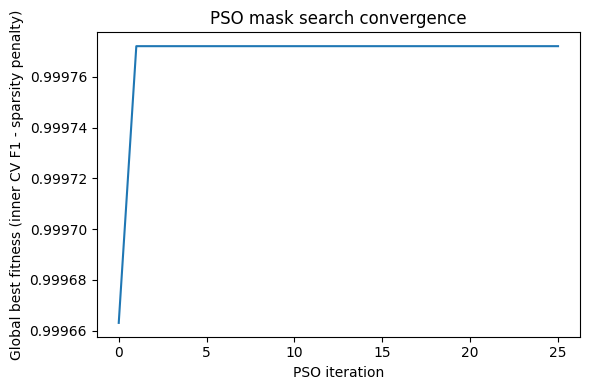

In [ ]:
# ---------------------------------------------------------------------------
# Particle swarm optimization over a real-valued mask m in [0,1]^d, d = 1,600.
# Fitness: inner cross-validated F1 of LinearSVC(Prune(X, m)) minus a sparsity penalty,
# matching Equation (7) and Algorithm 1 of the paper.
# ---------------------------------------------------------------------------

def prune(X, mask):
    return X * mask  # row-broadcast element-wise gating, Prune(X, m) = X (.) m

def pso_fitness(mask, X, y, folds=CV_FOLDS_FOR_FITNESS, lam=PSO_SPARSITY_LAMBDA):
    Xp = prune(X, mask)
    skf = StratifiedKFold(n_splits=folds, shuffle=True, random_state=SEED)
    f1s = []
    for tr_idx, va_idx in skf.split(Xp, y):
        scaler = MaxAbsScaler()
        Xtr = scaler.fit_transform(Xp[tr_idx])
        Xva = scaler.transform(Xp[va_idx])
        clf = LinearSVC(random_state=SEED, max_iter=3000)
        clf.fit(Xtr, y[tr_idx])
        pred = clf.predict(Xva)
        f1s.append(f1_score(y[va_idx], pred, zero_division=0))
    sparsity = float(np.sum(mask > 0.5)) / len(mask)
    return float(np.mean(f1s)) - lam * sparsity


def run_pso(X, y, d, n_particles=PSO_N_PARTICLES, n_iters=PSO_N_ITERS,
            omega=PSO_OMEGA, c1=PSO_C1, c2=PSO_C2, seed=SEED):
    rng = np.random.default_rng(seed)
    N = int(np.sqrt(d))
    off_diag_mask = ~np.eye(N, dtype=bool)

    # Sparse initialization: off-diagonal ~ U(0, 0.35), diagonal ~ U(0.3, 0.8), matching the paper.
    positions = np.zeros((n_particles, d))
    for p in range(n_particles):
        grid = np.zeros((N, N))
        grid[off_diag_mask] = rng.uniform(0.0, 0.35, size=off_diag_mask.sum())
        grid[np.eye(N, dtype=bool)] = rng.uniform(0.3, 0.8, size=N)
        positions[p] = grid.flatten()
    velocities = rng.uniform(-0.05, 0.05, size=(n_particles, d))

    personal_best_pos = positions.copy()
    personal_best_val = np.array([pso_fitness(positions[p], X, y) for p in range(n_particles)])
    g_idx = int(np.argmax(personal_best_val))
    global_best_pos = personal_best_pos[g_idx].copy()
    global_best_val = personal_best_val[g_idx]

    history = [global_best_val]
    for t in range(n_iters):
        for p in range(n_particles):
            r1 = rng.uniform(0, 1, size=d)
            r2 = rng.uniform(0, 1, size=d)
            velocities[p] = (omega * velocities[p]
                              + c1 * r1 * (personal_best_pos[p] - positions[p])
                              + c2 * r2 * (global_best_pos - positions[p]))
            positions[p] = np.clip(positions[p] + velocities[p], 0.0, 1.0)
            val = pso_fitness(positions[p], X, y)
            if val > personal_best_val[p]:
                personal_best_val[p] = val
                personal_best_pos[p] = positions[p].copy()
        g_idx = int(np.argmax(personal_best_val))
        if personal_best_val[g_idx] > global_best_val:
            global_best_val = personal_best_val[g_idx]
            global_best_pos = personal_best_pos[g_idx].copy()
        history.append(global_best_val)
        print(f'PSO iter {t+1}/{n_iters}  best fitness={global_best_val:.4f}  '
              f'active={(global_best_pos > 0.5).sum()}/{d}')
    return global_best_pos, history

print('Running PSO mask search on the training set '
      '(this is the slow step; matches the paper\'s offline training-stage cost)...')
t0 = time.time()
best_mask, pso_history = run_pso(X_train, y_train, d=X_train.shape[1])
pso_minutes = (time.time() - t0) / 60.0
print(f'PSO finished in {pso_minutes:.1f} min. Active coordinates: {(best_mask > 0.5).sum()} / {len(best_mask)}')

plt.figure(figsize=(6, 4))
plt.plot(pso_history)
plt.xlabel('PSO iteration')
plt.ylabel('Global best fitness (inner CV F1 - sparsity penalty)')
plt.title('PSO mask search convergence')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'pso_convergence.png', dpi=300)
plt.show()
np.save(RESULTS_DIR / 'best_mask.npy', best_mask)

## 9. Fit the final PhishSigma++ classifier (MaxAbsScaler + LinearSVC on the pruned features)

PhishSigma++ (ours): {'accuracy': 0.9998590953924194, 'precision': 1.0, 'recall': 0.9997011356843993, 'f1': 0.9998505455088925}


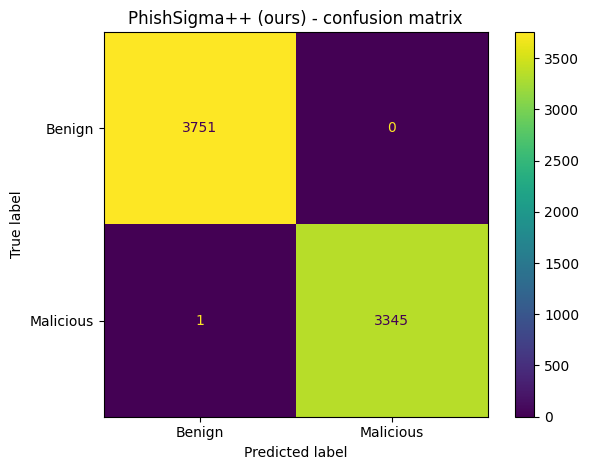

              precision    recall  f1-score   support

      Benign     0.9997    1.0000    0.9999      3751
   Malicious     1.0000    0.9997    0.9999      3346

    accuracy                         0.9999      7097
   macro avg     0.9999    0.9999    0.9999      7097
weighted avg     0.9999    0.9999    0.9999      7097



In [ ]:
# Fit the final classifier: MaxAbsScaler + LinearSVC on the PSO-pruned training features,
# matching Section 3.3 of the paper.
scaler = MaxAbsScaler()
X_train_pruned = scaler.fit_transform(prune(X_train, best_mask))
X_test_pruned = scaler.transform(prune(X_test, best_mask))

phishsigma_clf = LinearSVC(random_state=SEED, max_iter=5000)
phishsigma_clf.fit(X_train_pruned, y_train)
phishsigma_pred = phishsigma_clf.predict(X_test_pruned)

def metrics_from_preds(y_true, y_pred):
    return {
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'precision': float(precision_score(y_true, y_pred, zero_division=0)),
        'recall': float(recall_score(y_true, y_pred, zero_division=0)),
        'f1': float(f1_score(y_true, y_pred, zero_division=0)),
    }

phishsigma_metrics = metrics_from_preds(y_test, phishsigma_pred)
print('PhishSigma++ (ours):', phishsigma_metrics)
with open(RESULTS_DIR / 'phishsigma_metrics.json', 'w') as f:
    json.dump(phishsigma_metrics, f, indent=2)

cm = confusion_matrix(y_test, phishsigma_pred)
ConfusionMatrixDisplay(cm, display_labels=['Benign', 'Malicious']).plot(values_format='d')
plt.title('PhishSigma++ (ours) - confusion matrix')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'phishsigma_confusion_matrix.png', dpi=300)
plt.show()
print(classification_report(y_test, phishsigma_pred, target_names=['Benign', 'Malicious'], digits=4))

## 10. Component ablation: entity counts only vs dense mask vs PSO-pruned mask
Reproduces the shape of the paper's Table 4 (entity counts alone are already useful; the PSO-pruned relation graph should do better than both counts-only and the dense mask).

In [ ]:
# Component ablation, matching Table 4 of the paper:
#   (a) entity counts only  = diagonal-only mask
#   (b) all interaction features = dense mask (everything active)
#   (c) PSO-pruned relation graph = best_mask (already computed above)
diag_only_mask = np.zeros_like(best_mask)
N = N_ENTITY_TYPES
diag_only_mask.reshape(N, N)[np.eye(N, dtype=bool)] = 1.0
dense_mask = np.ones_like(best_mask)

def fit_eval_mask(mask, name):
    sc = MaxAbsScaler()
    Xtr = sc.fit_transform(prune(X_train, mask))
    Xte = sc.transform(prune(X_test, mask))
    clf = LinearSVC(random_state=SEED, max_iter=5000)
    clf.fit(Xtr, y_train)
    pred = clf.predict(Xte)
    m = metrics_from_preds(y_test, pred)
    print(name, m)
    return m

ablation_results = {
    'entity_counts_only': fit_eval_mask(diag_only_mask, 'Entity counts only (diagonal mask)'),
    'all_interaction_features': fit_eval_mask(dense_mask, 'All interaction features (dense mask)'),
    'pso_pruned_relation_graph': phishsigma_metrics,
}
ablation_df = pd.DataFrame(ablation_results).T
display(ablation_df)
ablation_df.to_csv(RESULTS_DIR / 'component_ablation.csv')

Entity counts only (diagonal mask) {'accuracy': 0.9998590953924194, 'precision': 1.0, 'recall': 0.9997011356843993, 'f1': 0.9998505455088925}
All interaction features (dense mask) {'accuracy': 0.9998590953924194, 'precision': 1.0, 'recall': 0.9997011356843993, 'f1': 0.9998505455088925}


,accuracy,precision,recall,f1
entity_counts_only,0.999859,1.0,0.999701,0.999851
all_interaction_features,0.999859,1.0,0.999701,0.999851
pso_pruned_relation_graph,0.999859,1.0,0.999701,0.999851


## 11. Baseline: TF-IDF + Multinomial Naive Bayes on body text
Stands in for the paper's token-based comparison filters (SpamBayes / a Naive-Bayes adapter).

In [ ]:
# Baseline: TF-IDF + Multinomial Naive Bayes on raw body text, standing in for the
# paper's token-based comparison filters (SpamBayes / a Naive-Bayes adapter).
def extract_body_only(raw_message):
    msg = parse_email(raw_message)
    if msg is None:
        return raw_message[:5000]
    return get_body_text(msg)[:5000]

body_train = [extract_body_only(r) for r in raw_train]
body_test = [extract_body_only(r) for r in raw_test]

nb_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=30000, stop_words='english')),
    ('clf', MultinomialNB()),
])
nb_pipeline.fit(body_train, y_train)
nb_pred = nb_pipeline.predict(body_test)
nb_metrics = metrics_from_preds(y_test, nb_pred)
print('TF-IDF + Naive Bayes (baseline):', nb_metrics)
with open(RESULTS_DIR / 'nb_baseline_metrics.json', 'w') as f:
    json.dump(nb_metrics, f, indent=2)

TF-IDF + Naive Bayes (baseline): {'accuracy': 0.8979850641115964, 'precision': 0.9924868519909842, 'recall': 0.789599521817095, 'f1': 0.8794940079893475}


## 12. Direct comparison and literature comparison (paper's Table 2)

In [ ]:
comparison = pd.DataFrame([
    {'model': 'TF-IDF + Naive Bayes (token baseline)', **nb_metrics},
    {'model': 'PhishSigma++ (typed entity-relation, ours)', **phishsigma_metrics},
])
display(comparison)
comparison.to_csv(RESULTS_DIR / 'comparison_ours.csv', index=False)

# Literature values reported in Table 2 of the paper on its own 29,142-email corpus.
paper_clean = {
    'RuleIOC_2020': {'f1': 0.2031, 'precision': 0.6830, 'recall': 0.1193, 'accuracy': 0.532},
    'SpamBayes_2011': {'f1': 0.9583, 'precision': 0.9967, 'recall': 0.9227, 'accuracy': 0.960},
    'SpamAssassin': {'f1': 0.1583, 'precision': 0.8739, 'recall': 0.0870, 'accuracy': 0.537},
    'Dima806_DistilBERT_2023': {'f1': 0.9367, 'precision': 0.9356, 'recall': 0.9379, 'accuracy': 0.937},
    'ElSlay_BERT_2024': {'f1': 0.8584, 'precision': 0.9565, 'recall': 0.7786, 'accuracy': 0.872},
    'E-PhishGen_NB_2025': {'f1': 0.8692, 'precision': 0.9793, 'recall': 0.7840, 'accuracy': 0.884},
    'PhishSigma++_paper': {'f1': 0.9675, 'precision': 0.9736, 'recall': 0.9614, 'accuracy': 0.968},
}
paper_clean_df = pd.DataFrame(paper_clean).T
paper_clean_df.loc['PhishSigma++_ours'] = phishsigma_metrics
paper_clean_df.loc['NaiveBayes_ours'] = nb_metrics
display(paper_clean_df)
paper_clean_df.to_csv(RESULTS_DIR / 'paper_vs_ours.csv')

,model,accuracy,precision,recall,f1
0,TF-IDF + Naive Bayes (token baseline),0.897985,0.992487,0.789600,0.879494
1,"PhishSigma++ (typed entity-relation, ours)",0.999859,1.000000,0.999701,0.999851


,f1,precision,recall,accuracy
RuleIOC_2020,0.203100,0.683000,0.119300,0.532000
SpamBayes_2011,0.958300,0.996700,0.922700,0.960000
SpamAssassin,0.158300,0.873900,0.087000,0.537000
Dima806_DistilBERT_2023,0.936700,0.935600,0.937900,0.937000
ElSlay_BERT_2024,0.858400,0.956500,0.778600,0.872000
E-PhishGen_NB_2025,0.869200,0.979300,0.784000,0.884000
PhishSigma++_paper,0.967500,0.973600,0.961400,0.968000
PhishSigma++_ours,0.999851,1.000000,0.999701,0.999859
NaiveBayes_ours,0.879494,0.992487,0.789600,0.897985


## 13. Adversarial robustness: non-adaptive Good Word body-padding attack
Matches Section 4.3 of the paper. Malicious test emails are padded with benign body text at increasing rates; headers and URLs are left untouched.

In [ ]:
# ---------------------------------------------------------------------------
# Adversarial robustness: non-adaptive "Good Word" body-padding attack, matching
# Section 4.3 of the paper. At injection rate rho, malicious TEST emails are padded
# with body text drawn from benign TRAIN emails so that a fraction rho of the final
# body is benign; headers and URLs are left untouched (as in the paper's threat model).
# ---------------------------------------------------------------------------
benign_body_pool = [b for b, y in zip(body_train, y_train) if y == 0]

def good_word_pad(body_text, rho, rng):
    if rho <= 0 or not benign_body_pool:
        return body_text
    filler = rng.choice(benign_body_pool)
    orig_words = body_text.split()
    filler_words = filler.split()
    if not orig_words:
        return filler_words and ' '.join(filler_words[:50]) or body_text
    n_total = max(len(orig_words), 20)
    n_filler = int(round(rho * n_total))
    n_keep = max(n_total - n_filler, 1)
    kept = orig_words[:n_keep]
    pad = filler_words[:n_filler] if filler_words else []
    return ' '.join(kept + pad)

def inject_into_raw(raw_message, rho, rng):
    """Re-inject padded body text back into the raw RFC822 message so header/URL
    extractors still see the real headers, matching the paper's protocol."""
    msg = parse_email(raw_message)
    if msg is None:
        return raw_message
    body = get_body_text(msg)
    padded_body = good_word_pad(body, rho, rng)
    try:
        if msg.is_multipart():
            for part in msg.walk():
                if part.get_content_type() == 'text/plain':
                    part.set_payload(padded_body)
                    break
            else:
                msg.set_payload(padded_body)
        else:
            msg.set_payload(padded_body)
        return msg.as_string()
    except Exception:
        return raw_message

rng = np.random.default_rng(SEED)
robustness_rows = []
malicious_test_idx = [i for i, y in enumerate(y_test) if y == 1]

for rho in GOOD_WORD_RATES:
    # Build the perturbed test set: malicious emails are padded, benign emails untouched.
    perturbed_raw = []
    perturbed_labels = []
    for i, (raw, y) in enumerate(zip(raw_test, y_test)):
        if y == 1:
            perturbed_raw.append(inject_into_raw(raw, rho, rng))
        else:
            perturbed_raw.append(raw)
        perturbed_labels.append(y)
    perturbed_labels = np.array(perturbed_labels)

    # PhishSigma++: re-extract typed entities/relations from the perturbed messages.
    feats = [build_collapsed_matrix(extract_entities(r)) for r in perturbed_raw]
    Xp = np.vstack(feats)
    Xp_scaled = scaler.transform(prune(Xp, best_mask))
    ps_pred = phishsigma_clf.predict(Xp_scaled)
    ps_f1 = f1_score(perturbed_labels, ps_pred, zero_division=0)

    # Baseline: re-extract body text and re-run the frozen TF-IDF+NB pipeline.
    perturbed_bodies = [extract_body_only(r) for r in perturbed_raw]
    nb_pred_p = nb_pipeline.predict(perturbed_bodies)
    nb_f1 = f1_score(perturbed_labels, nb_pred_p, zero_division=0)

    robustness_rows.append({'rho': rho, 'phishsigma_f1': ps_f1, 'naive_bayes_f1': nb_f1})
    print(f'rho={rho:.1f}  PhishSigma++ F1={ps_f1:.4f}  TF-IDF+NB F1={nb_f1:.4f}')

robustness_df = pd.DataFrame(robustness_rows)
display(robustness_df)
robustness_df.to_csv(RESULTS_DIR / 'good_word_robustness.csv', index=False)

plt.figure(figsize=(7, 5))
plt.plot(robustness_df['rho'], robustness_df['phishsigma_f1'], marker='o', label='PhishSigma++ (ours)')
plt.plot(robustness_df['rho'], robustness_df['naive_bayes_f1'], marker='s', label='TF-IDF + Naive Bayes (ours)')
plt.xlabel('Good Word injection rate (rho)')
plt.ylabel('F1-score')
plt.title('Robustness to body-padding attack: typed relations vs bag-of-words')
plt.legend()
plt.ylim(0, 1.05)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'good_word_robustness.png', dpi=300)
plt.show()

## 14. Compare our robustness curve with the paper's Table 5

In [ ]:
# Compare our robustness curve against the paper's Table 5 literature values.
paper_robustness = pd.DataFrame({
    'rho': [0.0, 0.2, 0.4, 0.6, 0.8],
    'paper_phishsigma_f1': [0.9675, 0.9642, 0.9642, 0.9612, 0.9579],
    'paper_spambayes_f1': [0.9672, 0.8080, 0.3299, 0.0633, 0.0243],
    'paper_distilbert_f1': [0.9367, 0.8472, 0.7395, 0.7345, 0.7284],
})
merged_robustness = robustness_df.merge(paper_robustness, on='rho')
display(merged_robustness)
merged_robustness.to_csv(RESULTS_DIR / 'robustness_paper_vs_ours.csv', index=False)

## 15. Evidence summary: which typed relations drove the decision
A lightweight analogue of the paper's analyst-facing tactic summary (Section 3.3 / Table 6).

In [ ]:
# Evidence / tactic summary: which type-pairs carry the largest retained mask weight,
# matching the paper's analyst-facing summary (Section 3.3 / Table 6). Purely descriptive,
# no separate explainer model - it reads directly off the PSO mask and SVM weights.
mask_grid = best_mask.reshape(N_ENTITY_TYPES, N_ENTITY_TYPES)
svm_weight_grid = np.zeros_like(mask_grid)
w = phishsigma_clf.coef_.flatten()
# Map SVM weights (over pruned/scaled features) back onto the retained mask positions.
active_idx = np.where(best_mask > 0.5)[0]
for pos, coord in enumerate(active_idx):
    if pos < len(w):
        svm_weight_grid[coord // N_ENTITY_TYPES, coord % N_ENTITY_TYPES] = w[pos]

top_k = 15
flat = np.abs(svm_weight_grid).flatten()
top_coords = np.argsort(flat)[::-1][:top_k]
evidence_rows = []
for c in top_coords:
    i, j = c // N_ENTITY_TYPES, c % N_ENTITY_TYPES
    if flat[c] <= 0:
        continue
    evidence_rows.append({
        'type_i': ENTITY_TYPES[i], 'type_j': ENTITY_TYPES[j],
        'mask_weight': float(mask_grid[i, j]), 'svm_weight': float(svm_weight_grid[i, j]),
    })
evidence_df = pd.DataFrame(evidence_rows)
display(evidence_df)
evidence_df.to_csv(RESULTS_DIR / 'top_evidence_relations.csv', index=False)

## 16. Error analysis: false negatives and false positives

In [ ]:
def error_summary(name, pred, raw_messages, labels):
    temp = pd.DataFrame({'label': labels, 'prediction': pred, 'raw_preview': [r[:300] for r in raw_messages]})
    fn = temp[(temp.label == 1) & (temp.prediction == 0)].copy()
    fp = temp[(temp.label == 0) & (temp.prediction == 1)].copy()
    print(name, 'false negatives:', len(fn), 'false positives:', len(fp))
    display(fn.head(5))
    display(fp.head(5))
    fn.to_csv(RESULTS_DIR / f'{name}_false_negatives.csv', index=False)
    fp.to_csv(RESULTS_DIR / f'{name}_false_positives.csv', index=False)

error_summary('phishsigma', phishsigma_pred, raw_test, y_test)
error_summary('naive_bayes', nb_pred, raw_test, y_test)